# Pearson correlation: sentiment vs returns

Original file name: `Correlation Analysis.ipynb`

**Runs from the data committed in this repository** (`data/derived/`, `data/prices/`, `data/tweet_counts/`, `data/annotation/`). Environment: see `requirements.txt` (Python 3.11, pandas 1.5.3). Outputs that displayed tweet text were cleared. Stored outputs are from the original run on the full dataset. Re-running on the text-free file reproduces every table except the two month-by-month tables, which shift in the third decimal (see README, Reproducibility).

In [1]:
import pandas as pd
import calendar
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
# Load dataset
btc = pd.read_csv("../data/prices/BTC-USD_1d_2021.csv")
eth = pd.read_csv("../data/prices/ETH-USD_1d_2021.csv")
tdf = pd.read_csv("../data/derived/twitter_sentiment_scores_2021.csv")

In [3]:
btc.head()
eth.head()
tdf.head()

In [4]:
val1=btc['Returns'].isna().sum()
val2=eth['Returns'].isna().sum()
val3=tdf['Compound'].isna().sum()

val1,val2,val3

(1, 1, 0)

In [5]:
tdf['Date'] = pd.to_datetime(tdf['timestamp']).dt.date
daily_sentiment = tdf.groupby('Date')['Compound'].mean().reset_index()

# Aggregation

In [6]:
# Convert 'Date' column to datetime format and set it as the index for resampling
btc['Date'] = pd.to_datetime(btc['Date'])
eth['Date'] = pd.to_datetime(eth['Date'])
daily_sentiment['Date'] = pd.to_datetime(daily_sentiment['Date'])

btc_weekly = btc.set_index('Date').resample('W-Fri')['Returns'].sum()
eth_weekly = eth.set_index('Date').resample('W-Fri')['Returns'].sum()
sentiment_weekly = daily_sentiment.set_index('Date').resample('W-Fri')['Compound'].mean()

In [7]:
btc_monthly = btc.set_index('Date').resample('M')['Returns'].sum()
eth_monthly = eth.set_index('Date').resample('M')['Returns'].sum()
sentiment_monthly = daily_sentiment.set_index('Date').resample('M')['Compound'].mean()

In [8]:
btc_weekly_merged = pd.merge(btc_weekly, sentiment_weekly, left_index=True, right_index=True)
eth_weekly_merged = pd.merge(eth_weekly, sentiment_weekly, left_index=True, right_index=True)

In [9]:
btc_monthly_merged = pd.merge(btc_monthly, sentiment_monthly, left_index=True, right_index=True)
eth_monthly_merged = pd.merge(eth_monthly, sentiment_monthly, left_index=True, right_index=True)

In [10]:
btc_daily_merged = pd.merge(daily_sentiment, btc, on='Date', how='inner')
eth_daily_merged = pd.merge(daily_sentiment, eth, on='Date', how='inner')

In [11]:
# Drop rows with NaN values
btc_daily_merged = btc_daily_merged.dropna(subset=['Compound', 'Returns'])
eth_daily_merged = eth_daily_merged.dropna(subset=['Compound', 'Returns'])

btc_weekly_merged = btc_weekly_merged.dropna(subset=['Compound', 'Returns'])
eth_weekly_merged = eth_weekly_merged.dropna(subset=['Compound', 'Returns'])

btc_monthly_merged = btc_monthly_merged.dropna(subset=['Compound', 'Returns'])
eth_monthly_merged = eth_monthly_merged.dropna(subset=['Compound', 'Returns'])

# Correlation Analysis

In [12]:
def calculate_correlation(data, col1, col2):
    correlation, p_value = pearsonr(data[col1], data[col2])
    return correlation, p_value

btc_daily_r, btc_daily_p = calculate_correlation(btc_daily_merged, 'Compound', 'Returns')
eth_daily_r, eth_daily_p = calculate_correlation(eth_daily_merged, 'Compound', 'Returns')

btc_weekly_r, btc_weekly_p = calculate_correlation(btc_weekly_merged, 'Compound', 'Returns')
eth_weekly_r, eth_weekly_p = calculate_correlation(eth_weekly_merged, 'Compound', 'Returns')

btc_monthly_r, btc_monthly_p = calculate_correlation(btc_monthly_merged, 'Compound', 'Returns')
eth_monthly_r, eth_monthly_p = calculate_correlation(eth_monthly_merged, 'Compound', 'Returns')

In [13]:
# Create a summary table
correlation_summary = {
    "Time Frame": ["Daily", "Weekly", "Monthly", "Daily", "Weekly", "Monthly"],
    "Cryptocurrency": ["Bitcoin"] * 3 + ["Ethereum"] * 3,
    "R Value": [btc_daily_r, btc_weekly_r, btc_monthly_r, eth_daily_r, eth_weekly_r, eth_monthly_r],
    "P Value": [btc_daily_p, btc_weekly_p, btc_monthly_p, eth_daily_p, eth_weekly_p, eth_monthly_p]
}
correlation_df = pd.DataFrame(correlation_summary)
correlation_df

,Time Frame,Cryptocurrency,R Value,P Value
0,Daily,Bitcoin,-0.039060,0.457514
1,Weekly,Bitcoin,-0.106357,0.448464
2,Monthly,Bitcoin,-0.114917,0.722118
3,Daily,Ethereum,-0.024510,0.641160
4,Weekly,Ethereum,-0.174936,0.210253
5,Monthly,Ethereum,-0.394489,0.204440


In [14]:
# Time Series Plot

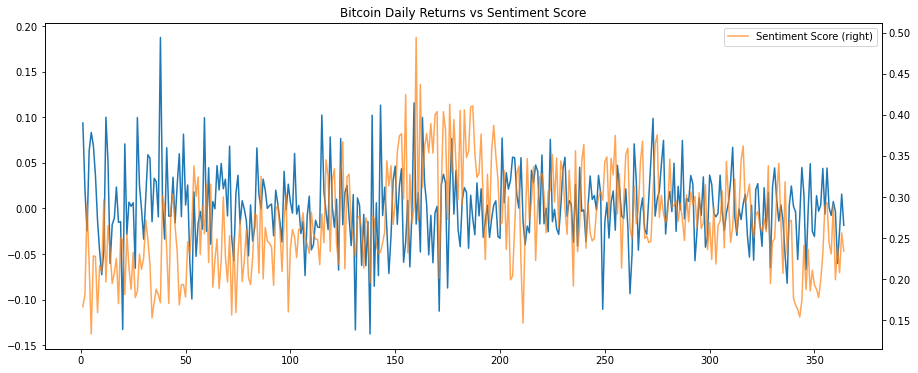

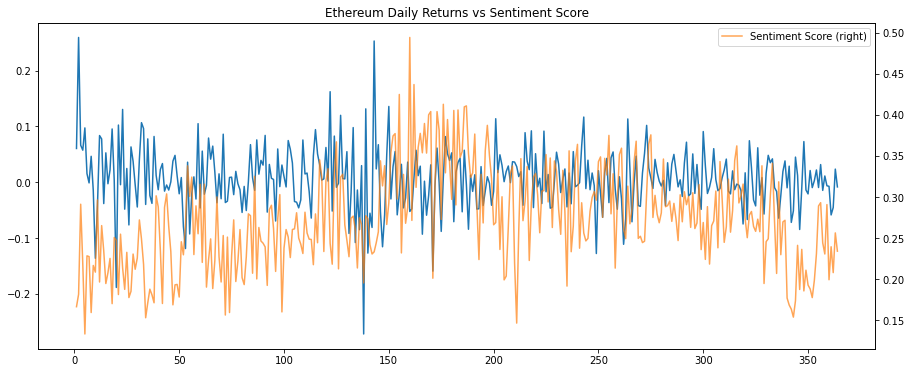

In [15]:
# Bitcoin
plt.figure(figsize=(15,6))
btc_daily_merged['Returns'].plot(label='Bitcoin Returns')
btc_daily_merged['Compound'].plot(secondary_y=True, label='Sentiment Score', alpha=0.7)
plt.title('Bitcoin Daily Returns vs Sentiment Score')
plt.legend(loc='best')
plt.show()

# Ethereum
plt.figure(figsize=(15,6))
eth_daily_merged['Returns'].plot(label='Ethereum Returns')
eth_daily_merged['Compound'].plot(secondary_y=True, label='Sentiment Score', alpha=0.7)
plt.title('Ethereum Daily Returns vs Sentiment Score')
plt.legend(loc='best')
plt.show()

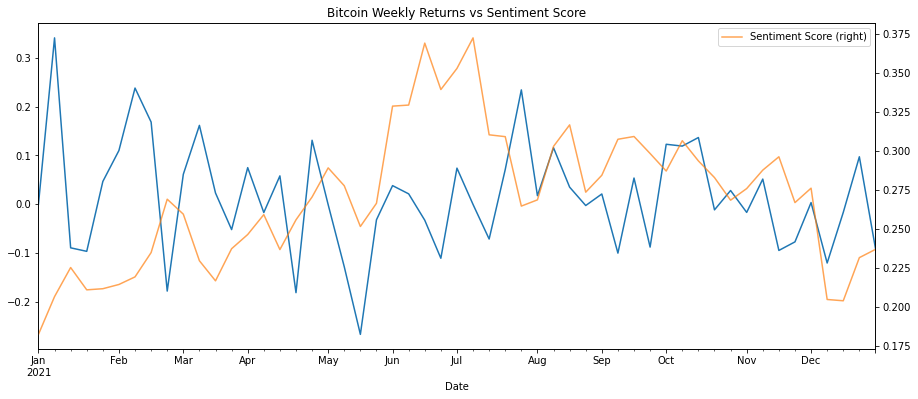

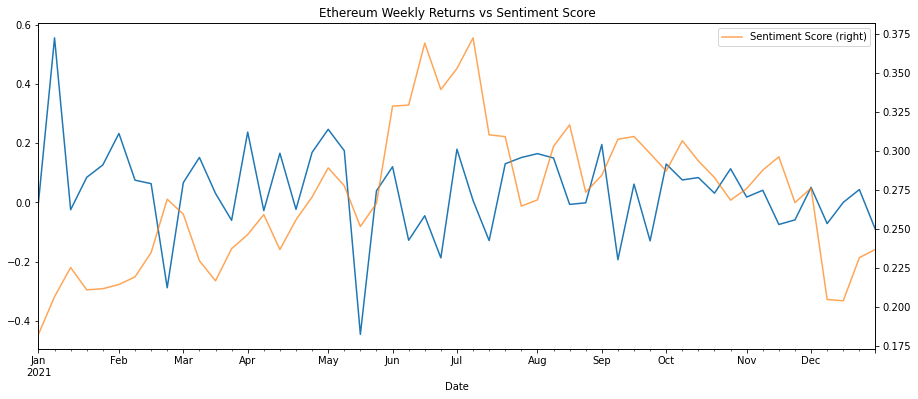

In [16]:
# Bitcoin
plt.figure(figsize=(15,6))
btc_weekly_merged['Returns'].plot(label='Bitcoin Returns')
btc_weekly_merged['Compound'].plot(secondary_y=True, label='Sentiment Score', alpha=0.7)
plt.title('Bitcoin Weekly Returns vs Sentiment Score')
plt.legend(loc='best')
plt.show()

# Ethereum
plt.figure(figsize=(15,6))
eth_weekly_merged['Returns'].plot(label='Ethereum Returns')
eth_weekly_merged['Compound'].plot(secondary_y=True, label='Sentiment Score', alpha=0.7)
plt.title('Ethereum Weekly Returns vs Sentiment Score')
plt.legend(loc='best')
plt.show()

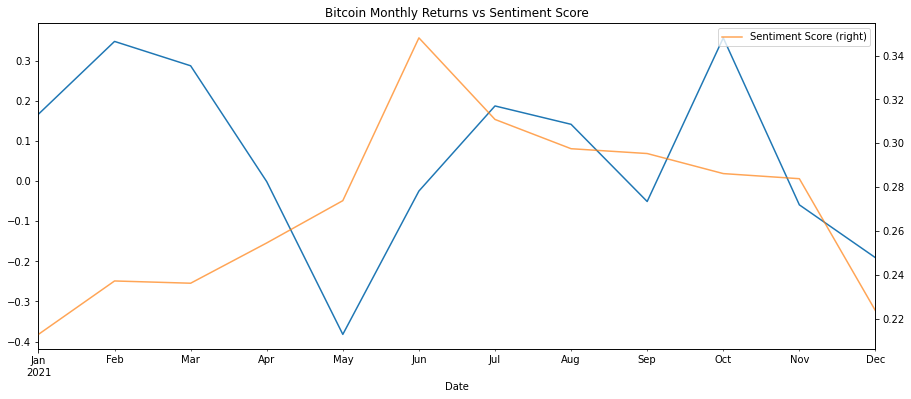

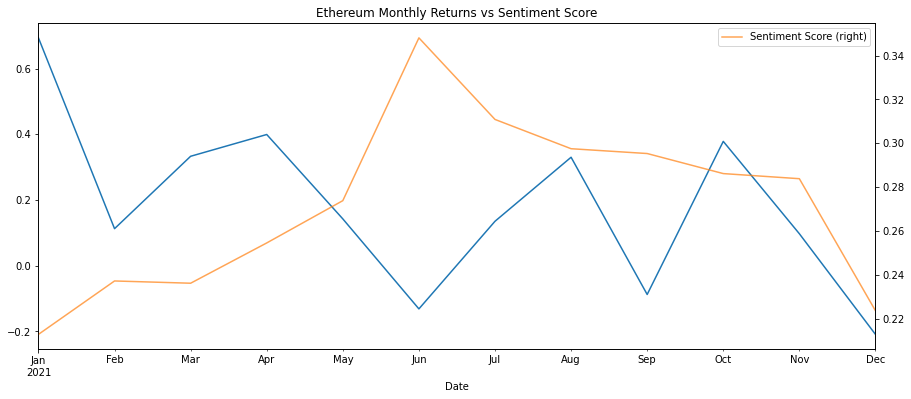

In [17]:
# Bitcoin
plt.figure(figsize=(15,6))
btc_monthly_merged['Returns'].plot(label='Bitcoin Returns')
btc_monthly_merged['Compound'].plot(secondary_y=True, label='Sentiment Score', alpha=0.7)
plt.title('Bitcoin Monthly Returns vs Sentiment Score')
plt.legend(loc='best')
plt.show()

# Ethereum
plt.figure(figsize=(15,6))
eth_monthly_merged['Returns'].plot(label='Ethereum Returns')
eth_monthly_merged['Compound'].plot(secondary_y=True, label='Sentiment Score', alpha=0.7)
plt.title('Ethereum Monthly Returns vs Sentiment Score')
plt.legend(loc='best')
plt.show()

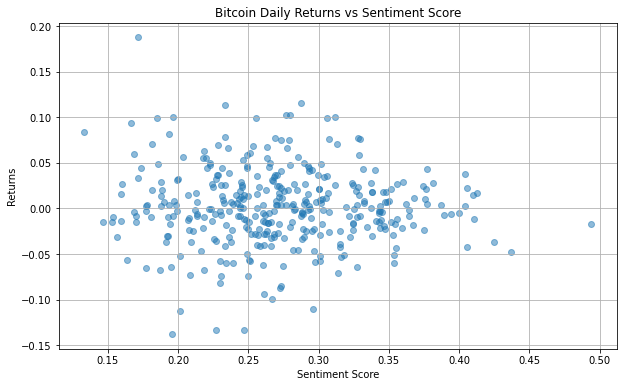

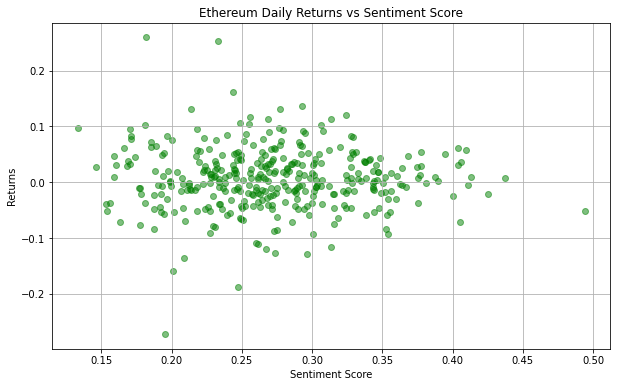

In [18]:
plt.figure(figsize=(10,6))
plt.scatter(btc_daily_merged['Compound'], btc_daily_merged['Returns'], alpha=0.5)
plt.title('Bitcoin Daily Returns vs Sentiment Score')
plt.xlabel('Sentiment Score')
plt.ylabel('Returns')
plt.grid(True)
plt.show()

plt.figure(figsize=(10,6))
plt.scatter(eth_daily_merged['Compound'], eth_daily_merged['Returns'], alpha=0.5, color='g')
plt.title('Ethereum Daily Returns vs Sentiment Score')
plt.xlabel('Sentiment Score')
plt.ylabel('Returns')
plt.grid(True)
plt.show()

# Scatter Plot

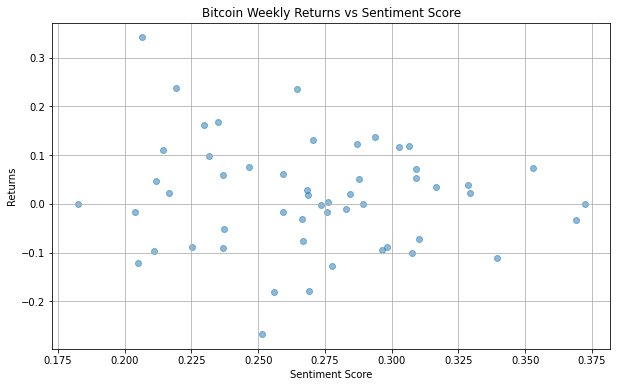

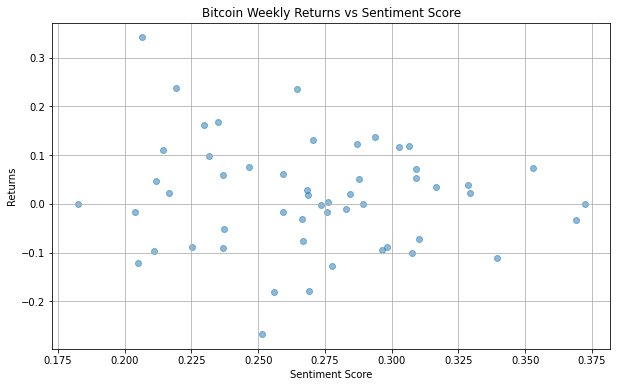

In [19]:
plt.figure(figsize=(10,6))
plt.scatter(btc_weekly_merged['Compound'], btc_weekly_merged['Returns'], alpha=0.5)
plt.title('Bitcoin Weekly Returns vs Sentiment Score')
plt.xlabel('Sentiment Score')
plt.ylabel('Returns')
plt.grid(True)
plt.show()

plt.figure(figsize=(10,6))
plt.scatter(btc_weekly_merged['Compound'], btc_weekly_merged['Returns'], alpha=0.5)
plt.title('Bitcoin Weekly Returns vs Sentiment Score')
plt.xlabel('Sentiment Score')
plt.ylabel('Returns')
plt.grid(True)
plt.show()

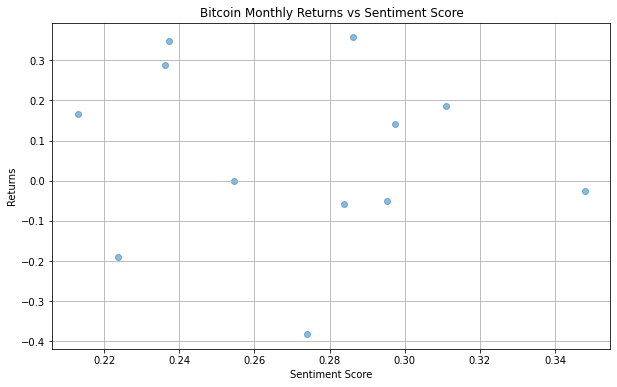

In [20]:
plt.figure(figsize=(10,6))
plt.scatter(btc_monthly_merged['Compound'], btc_monthly_merged['Returns'], alpha=0.5)
plt.title('Bitcoin Monthly Returns vs Sentiment Score')
plt.xlabel('Sentiment Score')
plt.ylabel('Returns')
plt.grid(True)
plt.show()

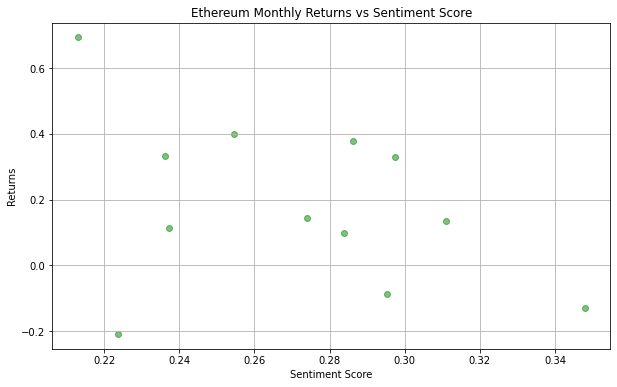

In [21]:
plt.figure(figsize=(10,6))
plt.scatter(eth_monthly_merged['Compound'], eth_monthly_merged['Returns'], alpha=0.5, color='g')
plt.title('Ethereum Monthly Returns vs Sentiment Score')
plt.xlabel('Sentiment Score')
plt.ylabel('Returns')
plt.grid(True)
plt.show()

# Month by Month Correlation

In [22]:
btc_data = pd.read_csv('../data/prices/BTC-USD_1d_2021.csv', parse_dates=['Date'], index_col='Date')
eth_data = pd.read_csv('../data/prices/ETH-USD_1d_2021.csv', parse_dates=['Date'], index_col='Date')
twitter_data = pd.read_csv('../data/derived/twitter_sentiment_scores_2021.csv', parse_dates=['timestamp'])
twitter_data['Date'] = twitter_data['timestamp'].dt.date
twitter_data.set_index('Date', inplace=True)

In [23]:
def monthly_correlation_with_pvalue(returns_data, sentiment_data):
    # Merge data on date
    merged_data = returns_data.merge(sentiment_data, left_index=True, right_index=True, how='inner')
    
    correlations = []
    for month in range(1, 13):  # For each month (from January to December)
        monthly_data = merged_data[merged_data.index.month == month].dropna()
        # Ensure there are at least two data points
        if len(monthly_data) > 1:
            r, p = pearsonr(monthly_data['Returns'], monthly_data['Compound'])
            correlations.append((calendar.month_name[month], r, p))
    return correlations

In [24]:
btc_monthly_correlations = monthly_correlation_with_pvalue(btc_data, twitter_data)
eth_monthly_correlations = monthly_correlation_with_pvalue(eth_data, twitter_data)

In [25]:
btc_monthly_correlations_df = pd.DataFrame(btc_monthly_correlations, columns=['Month', 'R Value', 'P Value'])
eth_monthly_correlations_df = pd.DataFrame(eth_monthly_correlations, columns=['Month', 'R Value', 'P Value'])

In [26]:
btc_monthly_correlations_df

,Month,R Value,P Value
0,January,-0.035006,0.022815
1,February,-0.047921,0.002148
2,March,-0.000666,0.965116
3,April,0.001889,0.902895
4,May,0.021423,0.153687
5,June,0.010773,0.492755
6,July,-0.045256,0.003781
7,August,0.022728,0.141780
8,September,0.008748,0.572086
9,October,0.004577,0.768737


In [27]:
eth_monthly_correlations_df

,Month,R Value,P Value
0,January,-0.029945,0.051511
1,February,-0.034585,0.026813
2,March,-0.008131,0.593267
3,April,0.008500,0.583071
4,May,0.016775,0.263970
5,June,0.039344,0.012214
6,July,-0.022365,0.152551
7,August,0.012823,0.407213
8,September,0.011697,0.450011
9,October,0.014350,0.356551


# Bar Plot

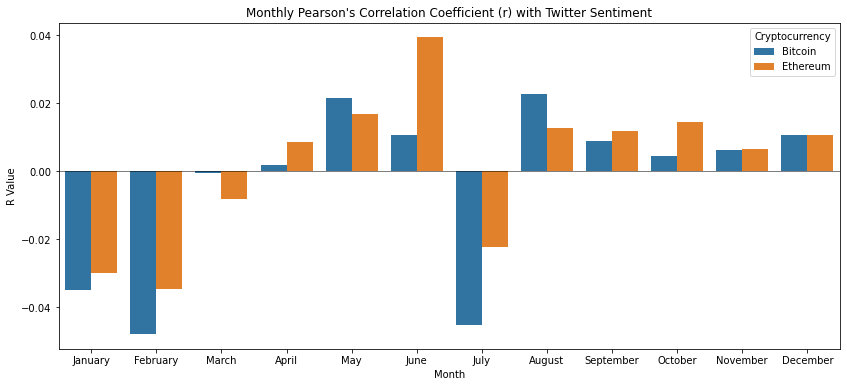

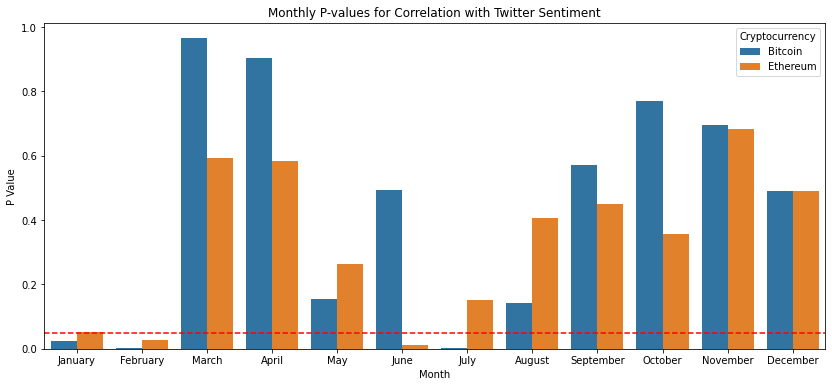

In [28]:
# Add 'Cryptocurrency' column
btc_monthly_correlations_df['Cryptocurrency'] = 'Bitcoin'
eth_monthly_correlations_df['Cryptocurrency'] = 'Ethereum'

# Concatenate
all_monthly_correlations = pd.concat([btc_monthly_correlations_df, eth_monthly_correlations_df])

# Plot
plt.figure(figsize=(14, 6))
sns.barplot(x="Month", y="R Value", hue="Cryptocurrency", data=all_monthly_correlations)
plt.axhline(0, color='black',linewidth=0.5)
plt.title("Monthly Pearson's Correlation Coefficient (r) with Twitter Sentiment")
plt.show()

# Setting up the figure and axis
plt.figure(figsize=(14, 6))
sns.barplot(x="Month", y="P Value", hue="Cryptocurrency", data=pd.concat([btc_monthly_correlations_df, eth_monthly_correlations_df]))
plt.axhline(0.05, color='red', linestyle='--')  # significance threshold
plt.title("Monthly P-values for Correlation with Twitter Sentiment")
plt.show()

# Scatter Plot

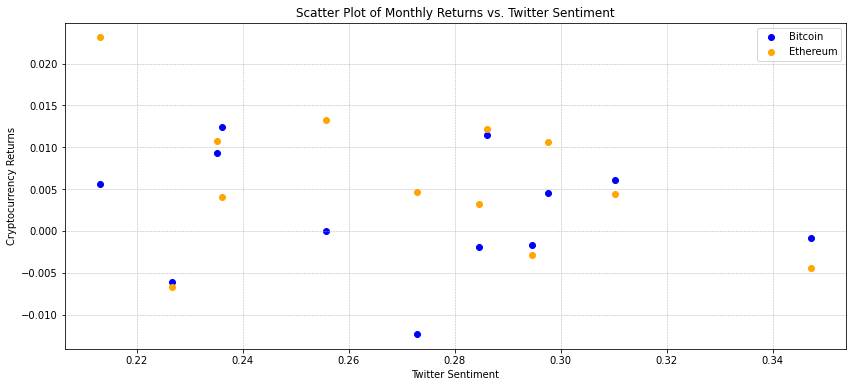

In [29]:
# Monthly aggregation for visualization
btc_monthly_avg = btc_data.resample('M')['Returns'].mean()
eth_monthly_avg = eth_data.resample('M')['Returns'].mean()

if 'Date' in twitter_data.columns:
    twitter_data.set_index('Date', inplace=True)

# Convert the index to DatetimeIndex
twitter_data.index = pd.to_datetime(twitter_data.index)

# Now, try resampling
twitter_monthly_avg = twitter_data.resample('M')['Compound'].mean()

# Scatter plot
plt.figure(figsize=(14, 6))
plt.scatter(twitter_monthly_avg, btc_monthly_avg, label="Bitcoin", color="blue")
plt.scatter(twitter_monthly_avg, eth_monthly_avg, label="Ethereum", color="orange")
plt.title("Scatter Plot of Monthly Returns vs. Twitter Sentiment")
plt.xlabel("Twitter Sentiment")
plt.ylabel("Cryptocurrency Returns")
plt.legend()
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.show()

# Rolling 7 day average Correlation

In [30]:
btc_daily_merged['Rolling_Sentiment'] = btc_daily_merged['Compound'].rolling(window=7).mean()
btc_daily_merged['Rolling_Returns'] = btc_daily_merged['Returns'].rolling(window=7).mean()

eth_daily_merged['Rolling_Sentiment'] = eth_daily_merged['Compound'].rolling(window=7).mean()
eth_daily_merged['Rolling_Returns'] = eth_daily_merged['Returns'].rolling(window=7).mean()

btc_rolling_corr_coeff, btc_rolling_p_value = pearsonr(btc_daily_merged.dropna()['Rolling_Returns'], btc_daily_merged.dropna()['Rolling_Sentiment'])
eth_rolling_corr_coeff, eth_rolling_p_value = pearsonr(eth_daily_merged.dropna()['Rolling_Returns'], eth_daily_merged.dropna()['Rolling_Sentiment'])

btc_rolling_corr_coeff, btc_rolling_p_value

(-0.1050673390802636, 0.046976019587224783)

In [31]:
eth_rolling_corr_coeff, eth_rolling_p_value

(-0.15228634740189825, 0.0038747848811776764)

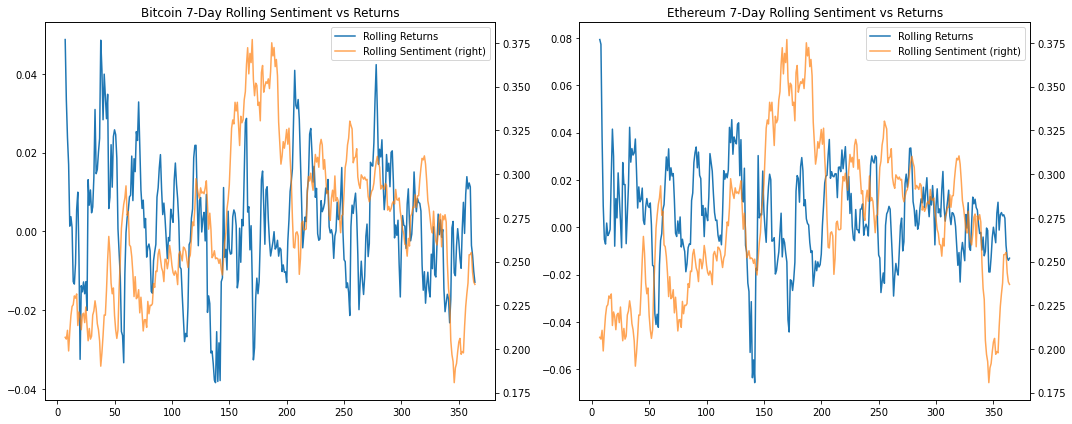

In [34]:
plt.figure(figsize=(15,6))

# Bitcoin
plt.subplot(1, 2, 1)
btc_daily_merged['Rolling_Returns'].plot(label='Rolling Returns', legend=True)
btc_daily_merged['Rolling_Sentiment'].plot(secondary_y=True, label='Rolling Sentiment', legend=True, alpha=0.7)
plt.title('Bitcoin 7-Day Rolling Sentiment vs Returns')

# Ethereum
plt.subplot(1, 2, 2)
eth_daily_merged['Rolling_Returns'].plot(label='Rolling Returns', legend=True)
eth_daily_merged['Rolling_Sentiment'].plot(secondary_y=True, label='Rolling Sentiment', legend=True, alpha=0.7)
plt.title('Ethereum 7-Day Rolling Sentiment vs Returns')

plt.tight_layout()
plt.show()

#  Significant Date Analysis

In [35]:
btc_daily_merged['Sentiment_Diff'] = btc_daily_merged['Rolling_Sentiment'].diff()
btc_significant_dates = btc_daily_merged.nlargest(3, 'Sentiment_Diff')['Date'].tolist() + btc_daily_merged.nsmallest(3, 'Sentiment_Diff')['Date'].tolist()
btc_significant_dates

[Timestamp('2021-06-28 00:00:00'),
 Timestamp('2021-02-24 00:00:00'),
 Timestamp('2021-08-07 00:00:00'),
 Timestamp('2021-07-13 00:00:00'),
 Timestamp('2021-12-10 00:00:00'),
 Timestamp('2021-12-07 00:00:00')]

In [36]:
eth_daily_merged['Sentiment_Diff'] = eth_daily_merged['Rolling_Sentiment'].diff()
eth_significant_dates = eth_daily_merged.nlargest(3, 'Sentiment_Diff')['Date'].tolist() + eth_daily_merged.nsmallest(3, 'Sentiment_Diff')['Date'].tolist()
eth_significant_dates

[Timestamp('2021-06-28 00:00:00'),
 Timestamp('2021-02-24 00:00:00'),
 Timestamp('2021-08-07 00:00:00'),
 Timestamp('2021-07-13 00:00:00'),
 Timestamp('2021-12-10 00:00:00'),
 Timestamp('2021-12-07 00:00:00')]

# Lagged Correlation Analysis

In [37]:
lag_values = [1, 2, 3]
btc_lagged_correlations = {}
eth_lagged_correlations = {}

for lag in lag_values:
    btc_shifted_sentiment = btc_daily_merged['Rolling_Sentiment'].shift(lag).dropna()
    btc_correlation, btc_p_value = pearsonr(btc_shifted_sentiment, btc_daily_merged['Rolling_Returns'].dropna().iloc[-len(btc_shifted_sentiment):])
    btc_lagged_correlations[lag] = (btc_correlation, btc_p_value)
    
    eth_shifted_sentiment = eth_daily_merged['Rolling_Sentiment'].shift(lag).dropna()
    eth_correlation, eth_p_value = pearsonr(eth_shifted_sentiment, eth_daily_merged['Rolling_Returns'].dropna().iloc[-len(eth_shifted_sentiment):])
    eth_lagged_correlations[lag] = (eth_correlation, eth_p_value)


In [38]:
# Display the lagged correlations for Bitcoin and Ethereum
print("Bitcoin Lagged Correlations:")
print("-" * 30)
for lag, values in btc_lagged_correlations.items():
    correlation, p_value = values
    print(f"Lag {lag} days:")
    print(f"Correlation Coefficient: {correlation:.4f}")
    print(f"P-value: {p_value:.4f}")
    print()

print("\nEthereum Lagged Correlations:")
print("-" * 30)
for lag, values in eth_lagged_correlations.items():
    correlation, p_value = values
    print(f"Lag {lag} days:")
    print(f"Correlation Coefficient: {correlation:.4f}")
    print(f"P-value: {p_value:.4f}")
    print()


Bitcoin Lagged Correlations:
------------------------------
Lag 1 days:
Correlation Coefficient: -0.1064
P-value: 0.0446

Lag 2 days:
Correlation Coefficient: -0.0989
P-value: 0.0623

Lag 3 days:
Correlation Coefficient: -0.0857
P-value: 0.1070


Ethereum Lagged Correlations:
------------------------------
Lag 1 days:
Correlation Coefficient: -0.1428
P-value: 0.0069

Lag 2 days:
Correlation Coefficient: -0.1222
P-value: 0.0211

Lag 3 days:
Correlation Coefficient: -0.1093
P-value: 0.0395



# Volatility  Correlation Analysis

In [39]:
btc_daily_merged['Rolling_Sentiment'] = btc_daily_merged['Compound'].rolling(window=7).mean()
eth_daily_merged['Rolling_Sentiment'] = eth_daily_merged['Compound'].rolling(window=7).mean()
btc_daily_merged['Volatility'] = btc_daily_merged['Returns'].rolling(window=7).std()
eth_daily_merged['Volatility'] = eth_daily_merged['Returns'].rolling(window=7).std()

btc_common_length = min(btc_daily_merged['Rolling_Sentiment'].dropna().shape[0], btc_daily_merged['Volatility'].dropna().shape[0])
eth_common_length = min(eth_daily_merged['Rolling_Sentiment'].dropna().shape[0], eth_daily_merged['Volatility'].dropna().shape[0])


btc_volatility_corr_coeff, btc_volatility_p_value = pearsonr(btc_daily_merged['Rolling_Sentiment'].dropna().iloc[-btc_common_length:], btc_daily_merged['Volatility'].dropna().iloc[-btc_common_length:])
eth_volatility_corr_coeff, eth_volatility_p_value = pearsonr(eth_daily_merged['Rolling_Sentiment'].dropna().iloc[-eth_common_length:], eth_daily_merged['Volatility'].dropna().iloc[-eth_common_length:])

In [40]:
btc_volatility_corr_coeff, btc_volatility_p_value

(-0.08317453428790024, 0.11619300619007064)

In [41]:
eth_volatility_corr_coeff, eth_volatility_p_value

(-0.06418227578440455, 0.22574674552674878)

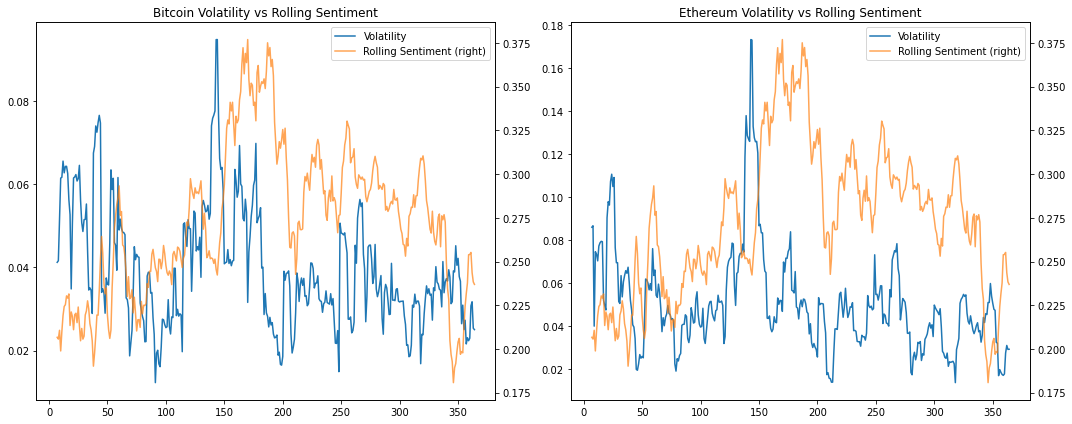

In [42]:
plt.figure(figsize=(15,6))

# Bitcoin
plt.subplot(1, 2, 1)
btc_daily_merged['Volatility'].plot(label='Volatility', legend=True)
btc_daily_merged['Rolling_Sentiment'].plot(secondary_y=True, label='Rolling Sentiment', legend=True, alpha=0.7)
plt.title('Bitcoin Volatility vs Rolling Sentiment')

# Ethereum
plt.subplot(1, 2, 2)
eth_daily_merged['Volatility'].plot(label='Volatility', legend=True)
eth_daily_merged['Rolling_Sentiment'].plot(secondary_y=True, label='Rolling Sentiment', legend=True, alpha=0.7)
plt.title('Ethereum Volatility vs Rolling Sentiment')

plt.tight_layout()
plt.show()
